# K-Nearest Neighbour
1. Consider the Cork Stoppers Data Set<p>
• Find the two most significant features according to the Kruskall-Wallis filter method

In [33]:
import numpy as np
import plotly.express as px
import pandas as pd
from scipy import stats
import os

datasets_folder = os.path.abspath(os.path.join(os.getcwd() ,"../..")) + "/Datasets/" #Set the path to the datasets folder, which is assumed to be two levels up from the current working directory and then inside a "Datasets" folder. Adjust this path as necessary based on your actual directory structure.

Labels=["Super","Average","Poor"]        
xlsFile=pd.read_excel(datasets_folder + "CORK_STOPPERS.XLS",
                      sheet_name="Data",
                      usecols=["C","ART","N.1","PRT","ARM","PRM","ARTG","NG","PRTG","RAAR","RAN"])
CorkStopp = pd.DataFrame(data=xlsFile.dropna())

fnames = CorkStopp.columns[1:]

ixSuper = np.where(CorkStopp['C']==1)
ixAverage = np.where(CorkStopp['C']==2)
ixPoor = np.where(CorkStopp['C']==3)

X = CorkStopp.to_numpy()[:,1:]
X = X.astype(float)

# Feature selection using Kruskall-Wallis
Hs = {}
for i in range(np.shape(X)[1]):
    st = stats.kruskal(X[ixPoor,i].flatten(), X[ixAverage,i].flatten(), X[ixSuper,i].flatten())
    Hs[fnames[i]]=st.statistic

Hs = sorted(Hs.items(), key=lambda x: x[1],reverse=True)  

print("Ranked features")

for f in Hs:
    print(f[0]+"-->"+str(f[1]))


Ranked features
ART-->121.58964258474009
PRM-->117.63782046335828
PRT-->115.74851860346449
ARTG-->115.21685092055695
ARM-->113.53079541575394
PRTG-->113.33179317347778
RAAR-->105.18901177731905
NG-->104.41349241044973
RAN-->94.28568910767306
N.1-->74.49926324214721


Build two datasets using the Hold-Out method. Consider 50% of the patterns for training and 50% for testing.

In [34]:
from sklearn.model_selection import train_test_split

# Prepare the data for training and testing
X = np.array([CorkStopp['ART'].to_numpy(),CorkStopp['PRM'].to_numpy()]).T
y = CorkStopp['C'].to_numpy()

# Split the data 
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    train_size = 0.5, test_size = 0.5,
                                                    random_state = 5)

#Obtain training standardization factors and standardize training and testing data
muTr=np.mean(X_train,axis=0)
stdTr=np.std(X_train,axis=0)

#Standardize the training and testing data using the training mean and standard deviation
X_train=(X_train-muTr)/stdTr
X_test=(X_test-muTr)/stdTr
print(X_train)

[[ 0.32982723 -0.22616073]
 [ 1.10344588  0.95152006]
 [-0.19998433 -0.12262835]
 [-1.02517756 -1.05873359]
 [ 1.99427948  1.38721881]
 [-0.89858541 -0.87755193]
 [-0.69228711 -0.74813646]
 [-0.21873872 -0.39008699]
 [-1.26898465 -1.02853665]
 [-0.85638803 -0.51087476]
 [ 1.69420922  0.74014146]
 [ 0.1704149   0.23542112]
 [-0.65008973 -0.97677046]
 [ 0.64396329  1.02054165]
 [-1.08144073 -0.88617963]
 [ 1.48322231  2.71588432]
 [ 0.07664295  0.08012256]
 [-0.74386168 -0.64029023]
 [-0.61258094 -0.56264095]
 [ 0.92527916  2.15077009]
 [ 0.15634911  0.30012886]
 [-0.33595367 -0.26498537]
 [-0.39690544 -0.48067782]
 [-0.87514242 -1.00265355]
 [ 0.86901599  0.37777814]
 [-0.2609361  -0.51950246]
 [ 0.21730088  0.14483029]
 [-0.94078279 -1.24854295]
 [-0.45316861 -0.21753303]
 [ 1.75516099  1.30956953]
 [-0.32188787 -0.00615442]
 [-1.00173457 -1.2269737 ]
 [-0.56569496 -0.83872729]
 [ 1.63325744  0.26993191]
 [ 0.23605527  2.37940409]
 [ 1.22534943  1.10681863]
 [ 1.56761707  1.27074489]
 

Perform a K-NN classification of the in order to discriminate between classes w1, w2 and w3. Consider k=1 and k=7. Plot the decision boundaries and the testing errors.

Error k=1 (%)=18.666666666666664
Error k=7 (%)=12.0


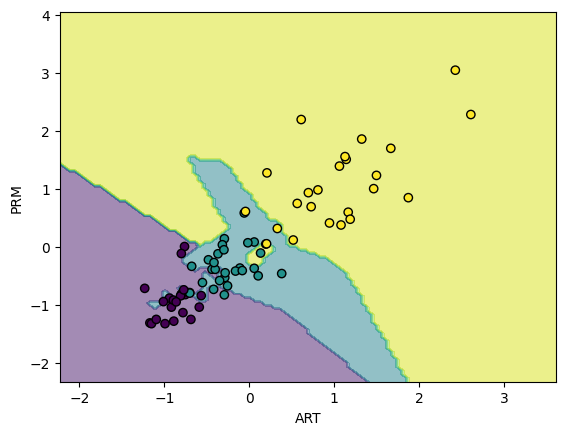

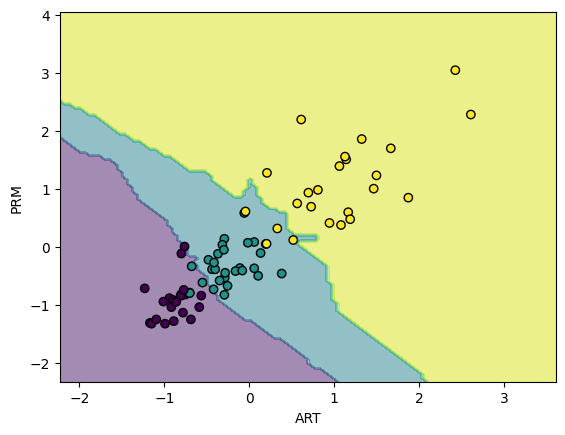

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

# Train and evaluate KNN classifiers with k=1 and k=7, and visualize the decision boundaries for both cases

#For k=1
knn1 = KNeighborsClassifier(n_neighbors=1)
knn1.fit(X_train, y_train)

yp = knn1.predict(X_test)

Hits = (np.where(yp==y_test)[0]).shape[0]

Acc = Hits/y_test.shape[0]

Err=(1-Acc)*100

print("Error k=1 (%)="+str(Err))

disp = DecisionBoundaryDisplay.from_estimator(knn1, X_test,
                                              response_method="predict",
                                              xlabel="ART", ylabel="PRM",
                                              alpha=0.5)
disp.ax_.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolor="k")


#For k=7
knn3 = KNeighborsClassifier(n_neighbors=7)
knn3.fit(X_train, y_train)

yp=knn3.predict(X_test)

Hits=(np.where(yp==y_test)[0]).shape[0]

Acc=Hits/y_test.shape[0]

Err=(1-Acc)*100

print("Error k=7 (%)="+str(Err))

disp = DecisionBoundaryDisplay.from_estimator(knn3, X_test,
                                              response_method="predict",
                                              xlabel="ART", ylabel="PRM",
                                              alpha=0.5)
disp.ax_.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolor="k")


Develop a schema to find the appropriate number of neighbors. Plot the decision boundaries and the testing error for the better solution.<b>
Note: A robust estimation implies the reporting of statistical measures that account for bias and variability, such as mean and variance.

Best k = 13
Error (%) = 17.333333333333336


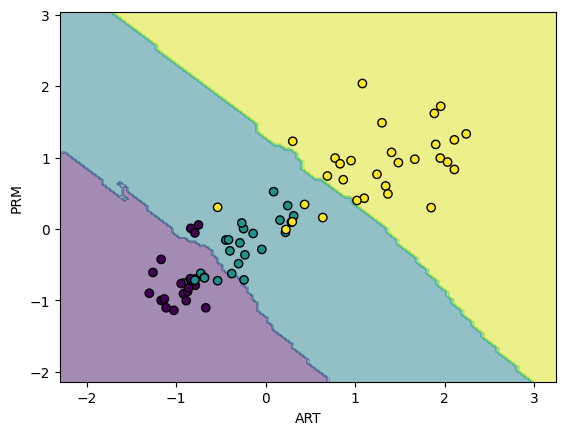

In [37]:
import plotly.express as px
runs = np.arange(0,30)
ks = np.arange(1,30,1)

errMat=np.zeros((runs.shape[0],ks.shape[0]))

for r in runs:#Create several training/testing partitions
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, test_size=0.5, random_state=r)
    
    #Normalize data -> obtain training standardization factors and standardize training and testing data
    muTr = np.mean(X_train,axis=0)
    stdTr = np.std(X_train,axis=0)
    X_train = (X_train-muTr)/stdTr
    X_test = (X_test-muTr)/stdTr
    
    ki=0
    for k in ks:#Evaluate different ks
        
        #fit knn
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train, y_train)
        yp = knn.predict(X_test)
        
        #Evaluate error
        Hits = (np.where(yp==y_test)[0]).shape[0]
        Acc = Hits/y_test.shape[0]
        
        #Store error
        errMat[r,ki] = (1-Acc)*100
        ki += 1

#at the end compute average error and error standard deviation
avgError = np.mean(errMat,axis=0)
stdError = np.std(errMat,axis=0)
 
#Display average error as function of k
fig = px.scatter(x = ks, y = avgError, error_y = stdError)
fig.update_layout(
    xaxis=dict(
        title=dict(
            text="k"
        )
    ),
    yaxis=dict(
        title=dict(
            text="Average Erros±Std"
        )
    ),
    font=dict(
        family="Courier New, monospace",
        size=18,
        color="RebeccaPurple"
    )
)
fig.show()

#Fing the best k
optK = ks[np.where(avgError==np.min(avgError))[0]][0]
print("Best k = "+str(optK))

#Train again knn with best k
knn = KNeighborsClassifier(n_neighbors=optK)
knn.fit(X_train, y_train)

yp=knn.predict(X_test)

Hits=(np.where(yp==y_test)[0]).shape[0]

Acc=Hits/y_test.shape[0]

Err=(1-Acc)*100

print("Error (%) = "+str(Err))

disp = DecisionBoundaryDisplay.from_estimator(
    knn, X_test, response_method="predict",
    xlabel="ART", ylabel="PRM",
    alpha=0.5,
)
disp.ax_.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolor="k")
